# imports



In [1]:
import numpy as np; import pandas as pd; import matplotlib.pyplot as plt; from PIL import Image;
import os
import urllib.request
import zipfile
import tarfile
import shutil
from numba import njit
from tqdm import trange

# чтение данных

In [2]:
def download_and_extract(url, extract_to='data'):
    # Создаем папку, если её нет
    os.makedirs(extract_to, exist_ok=True)
    # Получаем имя файла из URL
    filename = url.split('/')[-1]
    filepath = os.path.join(extract_to, filename)
    # Скачиваем файл
    urllib.request.urlretrieve(url, filepath)
        # Распаковываем в зависимости от типа архива
    with zipfile.ZipFile(filepath, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
    print(f"Архив успешно распакован в {extract_to}")

download_and_extract('https://www.cl.cam.ac.uk/research/dtg/attarchive/pub/data/att_faces.zip')

Архив успешно распакован в data


In [3]:
extract_to = 'data'
os.makedirs(extract_to, exist_ok=True)
final_dir = 'faces'
os.makedirs(final_dir, exist_ok=True)
for i in range(1, 41):
    src_dir = os.path.join(extract_to, f's{i}')
    for filename in os.listdir(src_dir):
                src_file = os.path.join(src_dir, filename)
                if os.path.isfile(src_file):
                    dst_file = os.path.join(final_dir, f's{i}_{filename}')
                    shutil.move(src_file, dst_file)

The ORL face database
---------------------

This directory contains a set of faces taken between April 1992 and
April 1994 at the Olivetti Research Laboratory in Cambridge, UK.

There are 10 different images of 40 distinct subjects. For some of the
subjects, the images were taken at different times, varying lighting
slightly, facial expressions (open/closed eyes, smiling/non-smiling)
and facial details (glasses/no-glasses).  All the images are taken
against a dark homogeneous background and the subjects are in
up-right, frontal position (with tolerance for some side movement).

The files are in PGM format and can be conveniently viewed using the 'xv'
program. The size of each image is 92x112, 8-bit grey levels. The images
are organised in 40 directories (one for each subject) named as:

		sX

where X indicates the subject number (between 1 and 40). In each directory
there are 10 different images of the selected subject named as:

		Y.pgm

where Y indicates which image for the specific subject (between 1 and 10).

When using these images, please give credit to Olivetti Research Laboratory.
A convenient reference is the face recognition work which uses some of
these images:

 F. Samaria and A. Harter
  "Parameterisation of a stochastic model for human face identification"
  2nd IEEE Workshop on Applications of Computer Vision
  December 1994, Sarasota (Florida).

The paper is available via anonymous ftp from quince.cam-orl.co.uk and is
stored in pub/users/fs/IEEE_workshop.ps.Z

If you have any question, please email Ferdinando Samaria: fs@cam-orl.co.uk


In [4]:
def convert_pgm_to_png(faces_dir):
    """Конвертирует все .pgm файлы в папке в .png"""
    for filename in os.listdir(faces_dir):
        if filename.lower().endswith('.pgm'):
            pgm_path = os.path.join(faces_dir, filename)
            png_path = os.path.join(faces_dir, os.path.splitext(filename)[0] + '.png')
                # Открываем PGM и сохраняем как PNG
            with Image.open(pgm_path) as img:
                img.save(png_path, 'PNG')
            os.remove(pgm_path)  # Удаляем оригинальный PGM
convert_pgm_to_png('faces')

In [6]:
mx = []

extract_num = lambda x: np.int64(x.split('_')[0][1:])
extract_check = lambda x: np.int64( x.split('_')[1].split('.')[0] )
d = {i:[] for i in range(1,41)}
for i in os.listdir('faces'):
  if extract_check(i) == 10:
    continue
  d[extract_num(i)].append(i)

for i in range(1,41):
  person=[]
  for j in range(9):
      path = os.path.join('faces',d[i][j])
      person.append(np.array(Image.open(path)).reshape(10304))
  mx += person
F = np.array(mx).T



mx = []

d2 = {i:[] for i in range(1,41)}
for i in os.listdir('faces'):
  if extract_check(i) != 10:
    continue
  d2[extract_num(i)].append(i)
for i in range(1,41):
  person=[]
  path = os.path.join('faces',d2[i][0])
  person.append(np.array(Image.open(path)).reshape(10304))
  mx += person
F_test = np.array(mx).T

# работа

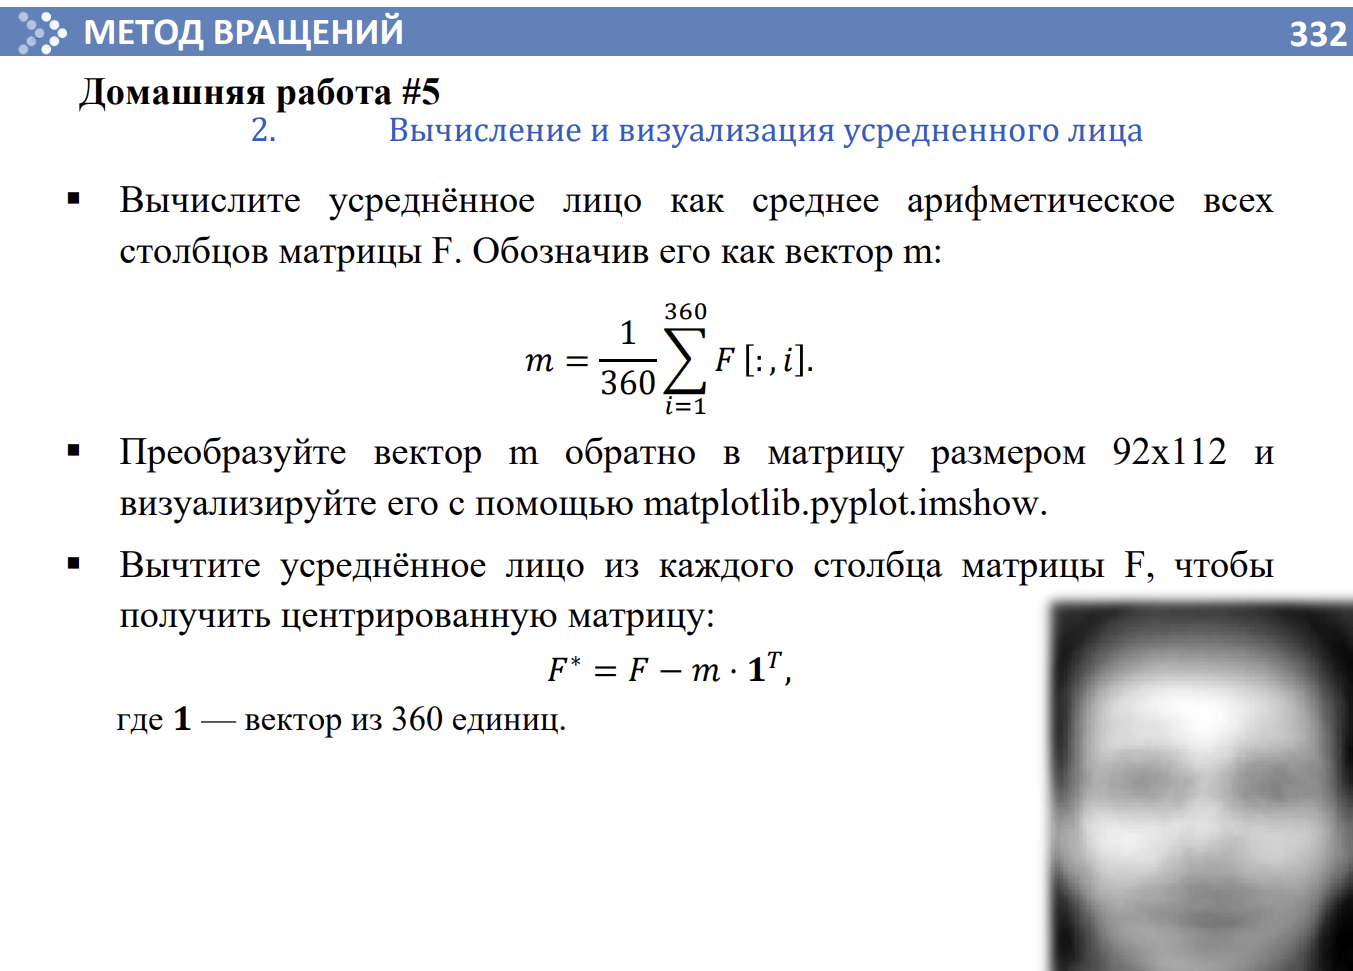

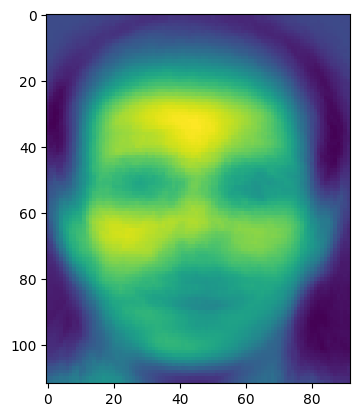

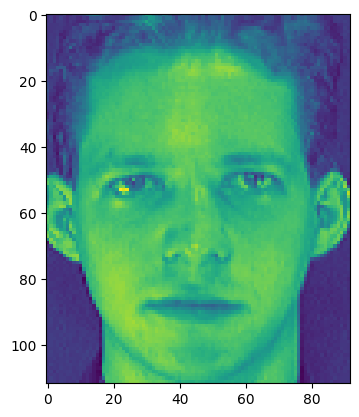

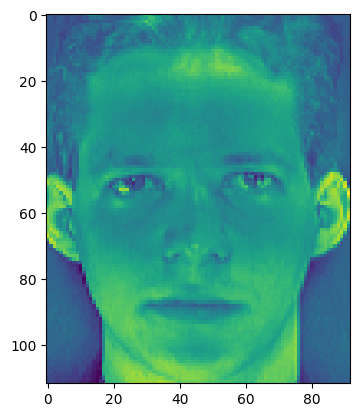

In [7]:
m = 1/360 * np.sum(F,axis=1)
plt.imshow(m.reshape(112 , 92));plt.show()
F_ = F - np.repeat(m,360).reshape(10304,360)
plt.imshow(F[:,0].reshape(112,92));plt.show()
plt.imshow(F_[:,0].reshape(112,92));plt.show()

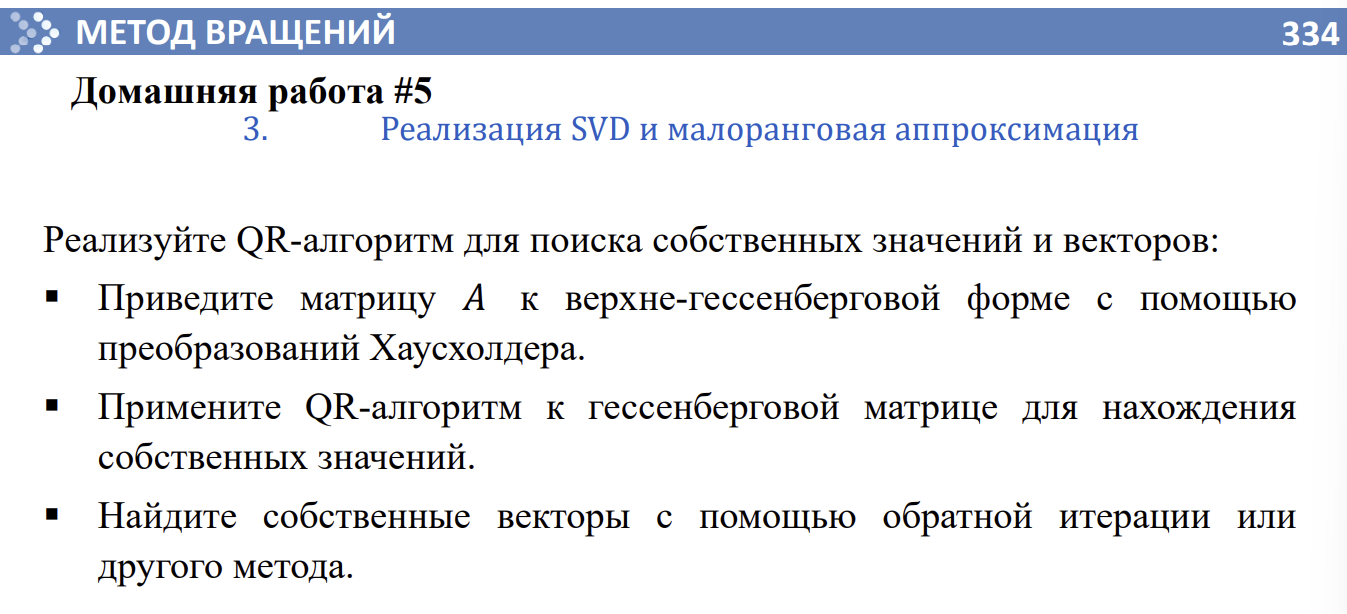

###Алгоритм Хаусхолдера для нахождения трехдиагональной матрицы:

In [8]:
A = F_.T @ F_
def Householder(X):
  B = X.copy()
  n = B.shape[0]
  for i in range(n-1):
    x = B[i+1:,i]
    sigma = -1 * np.sign(x[0]) * np.sqrt((x**2).sum())
    se = np.zeros(x.shape)
    se[0] = sigma
    v = x.copy() - se
    vn = np.sqrt((v**2).sum())
    v/=vn
    v=v.reshape(1,-1)
    H = np.eye(x.shape[0]) - 2 * v.T@v
    Hp = np.eye(B.shape[0])
    Hp[i+1:,i+1:] = H
    B = Hp @ B @ Hp
  return B
H = Householder(A)

###QR алгоритм со сдвигом (QR step shift):

In [9]:

@njit
def norm(k):
    return np.sqrt((k * k).sum())

@njit
def QR_dec(A):
    n, m = A.shape
    Q = np.zeros((n, m),dtype=np.float64)
    for i in range(m):
        u = A[:, i].copy()
        for j in range(i):
            proj = (Q[:, j] @ u) * Q[:, j]
            u -= proj
        u_norm = norm(u)
        if u_norm > 1e-12:
            Q[:, i] = u / u_norm
    R = Q.T @ A
    return Q, R

@njit
def QR_step(Ak):
    Q, R = QR_dec(Ak)
    return R @ Q

def QR_step_shift(Ak):
    mu = Ak[-1, -1]
    Q, R = QR_dec(Ak - mu * np.eye(Ak.shape[0]))
    return R @ Q + mu * np.eye(Ak.shape[0])

def QR_alg(A, tol=1e-9, miter=1000):
    Ak = A.copy()
    n = A.shape[0]
    for _ in trange(miter):
        off = False
        a = abs(np.diag(Ak,k=-1))
        if np.all(a<tol):
          break
        Ak = QR_step_shift(Ak)
    return np.array([Ak[i, i] for i in range(n)])



eigenvalues = QR_alg(H,miter = 5_000, tol= 1e-12)
true_eigenvalues = np.linalg.eigvals(H)

  0%|          | 0/5000 [00:00<?, ?it/s]<ipython-input-9-ff9e58c2f393>:13: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 1, 'C', False, aligned=True))
  proj = (Q[:, j] @ u) * Q[:, j]
100%|██████████| 5000/5000 [14:51<00:00,  5.61it/s]


###Проверим с тем, что выдает numpy:

In [10]:
# Полученные значения из QR-алгоритма
eig_qr = eigenvalues

# Точные значения
eig_real = true_eigenvalues

# Сравнение
print("QR алгоритм:     ", np.round(np.sort(eig_qr), 6))
print("Точные значения: ", np.round(np.sort(eig_real), 6))
print("Максимальная ошибка:", np.max(np.abs(np.sort(eig_qr) - np.sort(eig_real))))
print(np.round(np.sort(eig_qr), 6) - np.round(np.sort(eig_real), 6))

QR алгоритм:      [-0.00000000e+00  4.34525315e+05  4.59321153e+05  5.02989201e+05
  5.37309128e+05  5.54289130e+05  5.79374220e+05  6.23762241e+05
  6.33355112e+05  6.50520426e+05  6.59744227e+05  6.73417896e+05
  6.98267879e+05  7.19322266e+05  7.35248282e+05  7.46519650e+05
  7.53991171e+05  7.76379479e+05  7.80794083e+05  7.89854919e+05
  8.12762121e+05  8.13299367e+05  8.21190277e+05  8.24462835e+05
  8.47210240e+05  8.62040599e+05  8.62625911e+05  8.77273843e+05
  8.80328781e+05  8.92220186e+05  9.16056076e+05  9.19419042e+05
  9.31990584e+05  9.40703115e+05  9.47327916e+05  9.52509395e+05
  9.63593300e+05  9.77839307e+05  9.79586029e+05  9.84694031e+05
  9.96003514e+05  9.99773353e+05  1.01059263e+06  1.01784742e+06
  1.02215343e+06  1.03685901e+06  1.04183910e+06  1.05179791e+06
  1.06204117e+06  1.06666862e+06  1.07129494e+06  1.08001755e+06
  1.09238154e+06  1.09914052e+06  1.10709581e+06  1.10994172e+06
  1.12195006e+06  1.13272353e+06  1.13718497e+06  1.15155217e+06
  1.157

###Вычислим методом обратной итерации собственные вектора:

In [11]:
@njit
def eye(n):
    I = np.zeros((n, n))
    for i in range(n):
        I[i, i] = 1.0
    return I

@njit
def lu_decomp(A):
    n = A.shape[0]
    L = np.zeros_like(A)
    U = A.copy()
    for i in range(n):
        L[i, i] = 1.0
        for j in range(i+1, n):
            factor = U[j, i] / U[i, i]
            L[j, i] = factor
            U[j] -= factor * U[i]
    return L, U

@njit
def solve_lu(L, U, b):
    n = L.shape[0]
    y = np.zeros(n)
    for i in range(n):
        y[i] = b[i] - L[i, :i] @ y[:i]
    x = np.zeros(n)
    for i in range(n-1, -1, -1):
        x[i] = (y[i] - U[i, i+1:] @ x[i+1:]) / U[i, i]
    return x

@njit
def rayleigh_inv_iter(A, eigenvalue, tol=1e-10, max_iter=100):
    n = A.shape[0]
    x = np.random.rand(n)
    x /= norm(x)
    mu = eigenvalue

    for _ in range(max_iter):
        B = A - mu * eye(n)
        L, U = lu_decomp(B)
        y = solve_lu(L, U, x)
        y_norm = norm(y)
        if y_norm < tol:
            break
        x_new = y / y_norm
        if norm(x_new - x) < tol:
            break
        x = x_new

    return x

def compute_orthonormal_basis(A, eigenvalues):
    n = A.shape[0]
    basis = []
    for i in trange(len(eigenvalues)):
        v = rayleigh_inv_iter(A, eigenvalues[i])
        for b in basis:
            v -= np.dot(v, b) * b
        v /= norm(v)
        basis.append(v)
    return np.array(basis).T


eigenvectors = compute_orthonormal_basis(A, eigenvalues)

100%|██████████| 360/360 [12:53<00:00,  2.15s/it]


In [12]:
for i, v in enumerate(eigenvectors):
    print(np.round(A @ v - eigenvalues[i] * v, 6))

Выходные данные были обрезаны до нескольких последних строк (5000).
 -4.77548577e+06 -2.84566836e+06  7.23376531e+05 -1.95417266e+06
 -1.93401216e+06 -4.63091234e+06  6.10319060e+05 -4.06483851e+06
 -4.65321766e+06 -2.85617267e+06 -1.42282515e+06  4.03806825e+06
  4.79517207e+06  2.84293063e+06  5.23889154e+06  4.31437599e+06
  1.57099288e+06  3.07521460e+06  3.22260113e+06  4.70950738e+06
  2.54705931e+06  3.76145720e+06  3.13442343e+06  1.77244740e+06
  3.94590481e+06  2.83117196e+06  3.99694348e+06  2.67629420e+06
  3.15412167e+06  2.10727355e+06  1.45965601e+06  3.20559935e+06
  9.46838002e+05  2.45121208e+06  1.76599325e+06  1.48480673e+06
  1.90305347e+06  2.82569775e+06  3.98348225e+06 -1.07349471e+06
  3.71282035e+06 -1.16584151e+05  4.83795926e+06 -2.90525484e+04
  4.81510465e+05  8.25382545e+05  4.06669250e+06  2.12599485e+06
  5.76847631e+06  5.29610834e+06  3.28229453e+06  1.52269375e+06
  1.55999663e+06  2.41468760e+06  6.27657401e+06  2.62642868e+06
 -4.76616873e+06 -5.55

###Сингулярное разложение

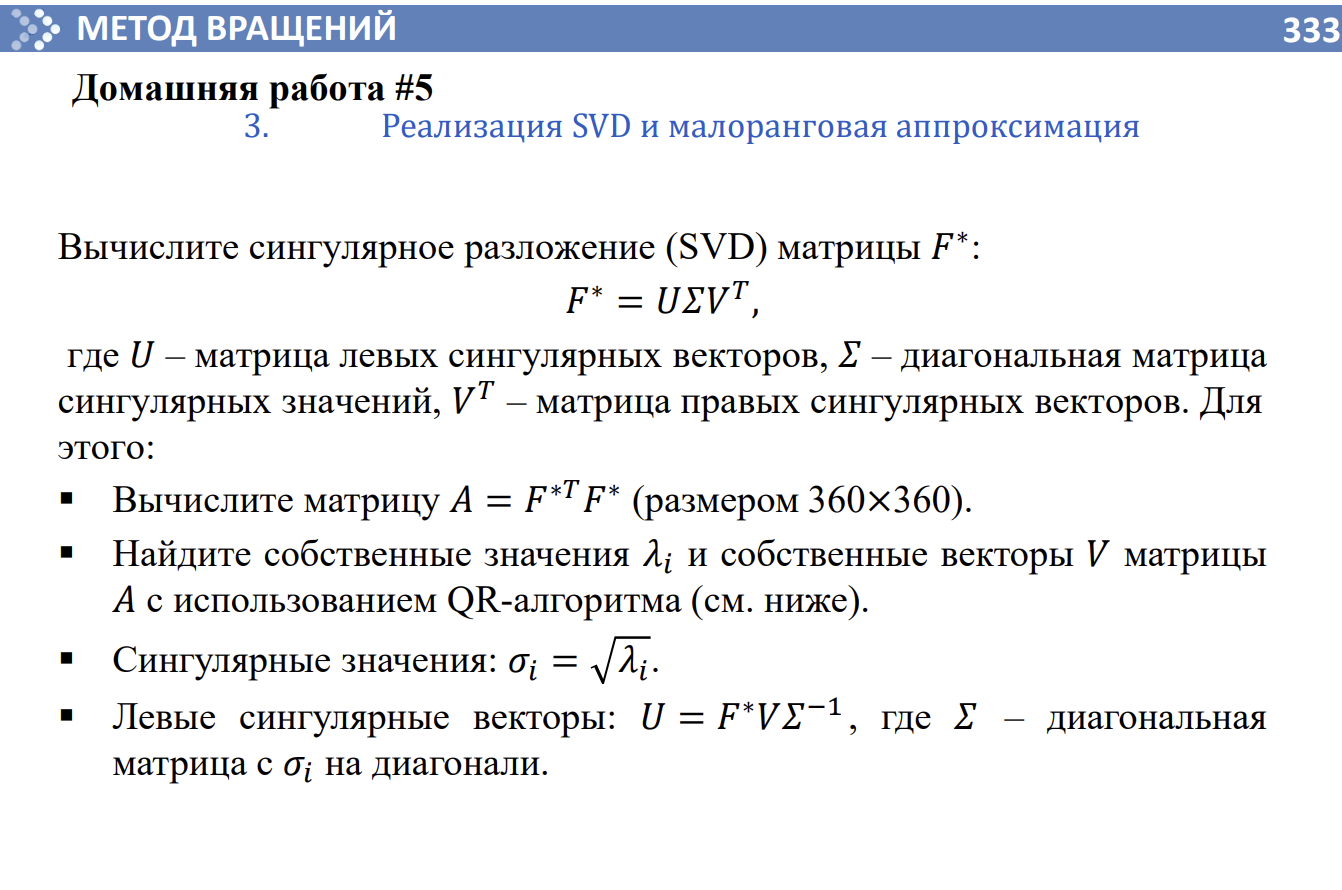

In [13]:
@njit
def eye(n):
    I = np.zeros((n, n))
    for i in range(n):
        I[i, i] = 1.0
    return I

@njit
def solve_gauss(A, b):
    A = A.copy()
    b = b.copy()
    n = len(b)

    for i in range(n):
        max_row = i + np.argmax(np.abs(A[i:, i]))
        if np.abs(A[max_row, i]) < 1e-12:
            raise ZeroDivisionError("Матрица сингулярна(")

        if max_row != i:
            A[i], A[max_row] = A[max_row].copy(), A[i].copy()
            b[i], b[max_row] = b[max_row], b[i]

        for j in range(i + 1, n):
            factor = A[j, i] / A[i, i]
            for k in range(i, n):
                A[j, k] -= factor * A[i, k]
            b[j] -= factor * b[i]

    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        if np.abs(A[i, i]) < 1e-12:
            raise ZeroDivisionError("Матрица сингулярна(")
        s = 0.0
        for j in range(i + 1, n):
            s += A[i, j] * x[j]
        x[i] = (b[i] - s) / A[i, i]

    return x

@njit
def inverse_matrix(A):
    n = A.shape[0]
    I = eye(n)
    A_inv = np.zeros((n, n))
    for i in range(n):
        e = I[:, i]
        A_inv[:, i] = solve_gauss(A, e)
    return A_inv

eig = np.where(eigenvalues < 0, 1e-8, eigenvalues)
sigma_mx_inv = inverse_matrix(np.eye(len(eig)) * np.sqrt(eig.T))
U = F_ @ eigenvectors @ sigma_mx_inv

###Малоранговая аппроксимация

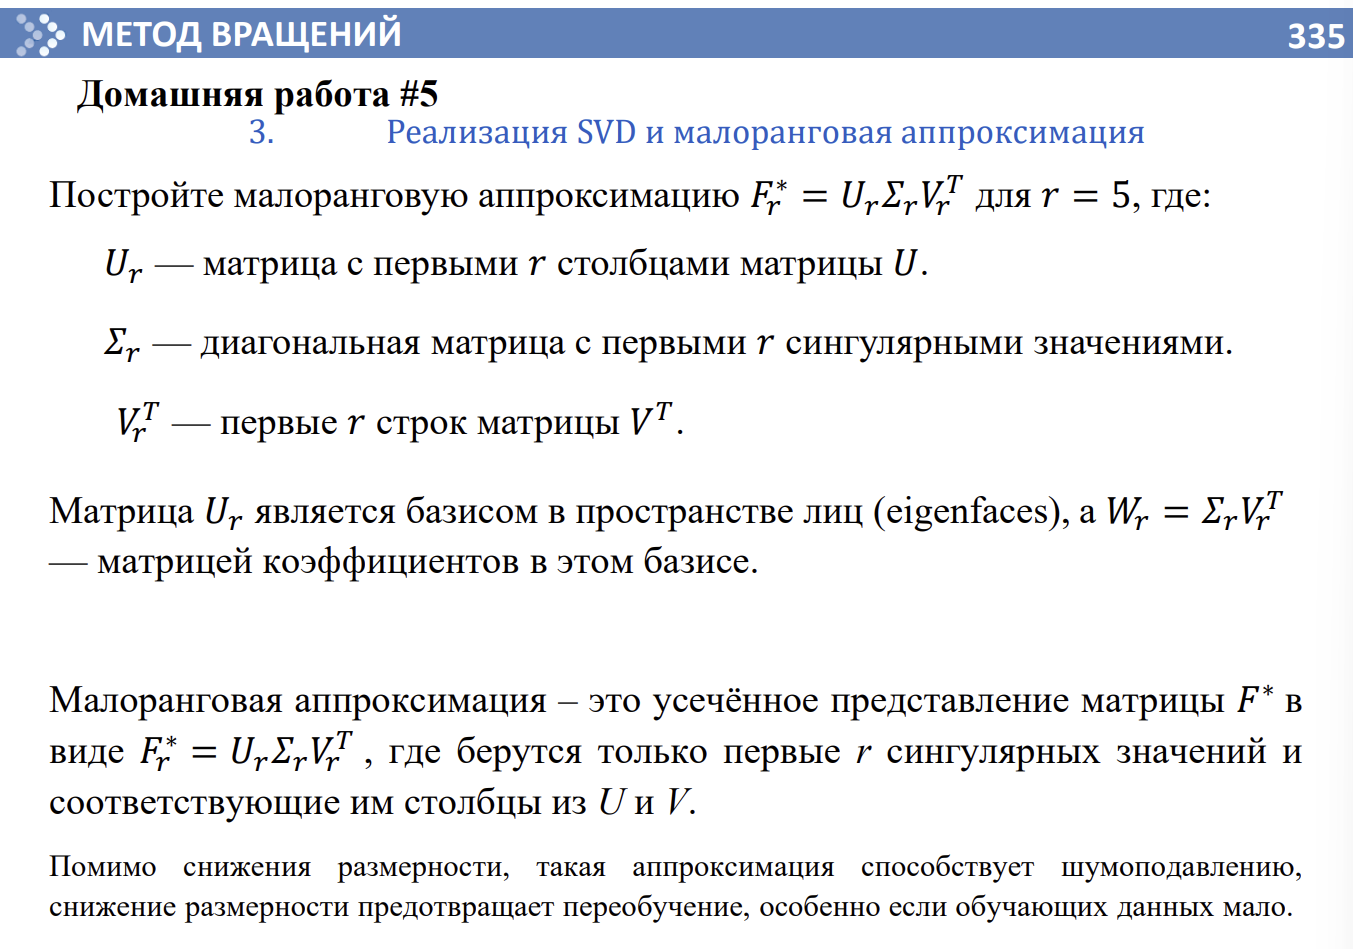

In [14]:
if type(eigenvectors) == list:
  eigenvectors = np.array(eigenvectors)
eig_val_vec_u = list(zip(eigenvalues, eigenvectors.T,U.T))
eig_val_vec_u.sort(key=lambda x: -x[0])
r = 5
F_r = sum(s * (u[:, None] @ v[None, :]) for s, v, u in eig_val_vec_u[:r])

###Eigenface

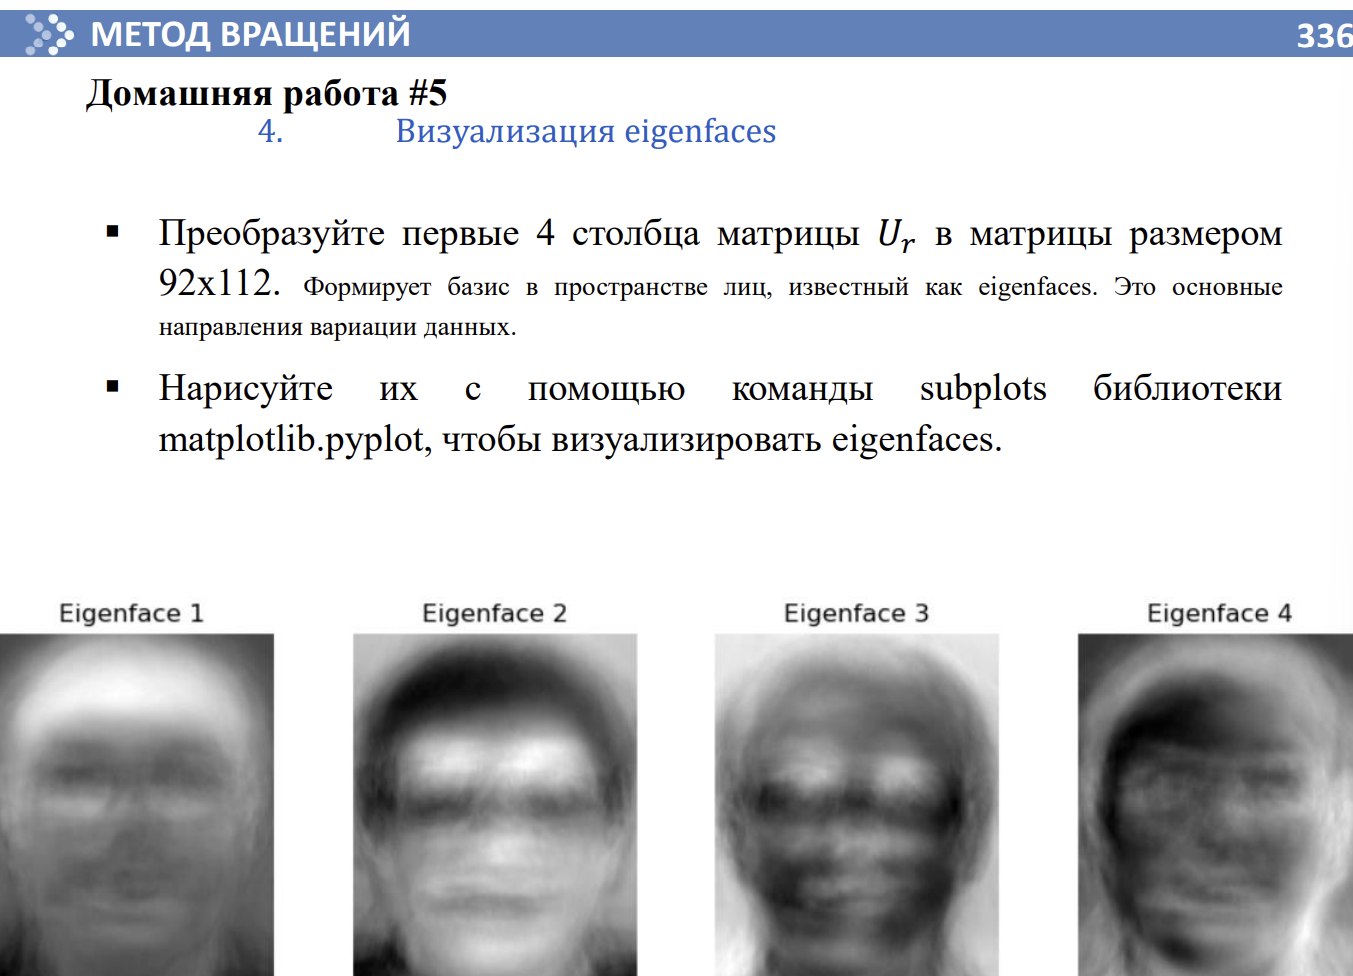

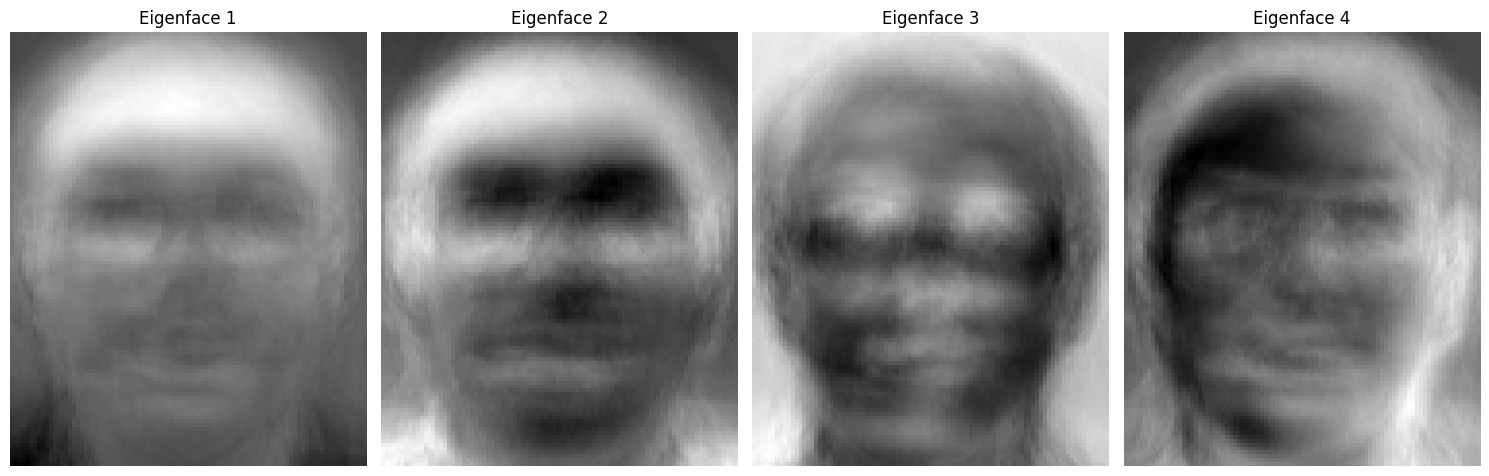

In [15]:
ur = [i[2] for i in eig_val_vec_u[:4]]

plt.figure(figsize=(15, 5))
for idx, img in enumerate(ur, 1):
    plt.subplot(1, 4, idx)
    plt.imshow(img.reshape(112, 92), cmap='gray')
    plt.title(f'Eigenface {idx}')
    plt.axis('off')
plt.tight_layout()
plt.show()

###Спроецируем F и F_test на U_r

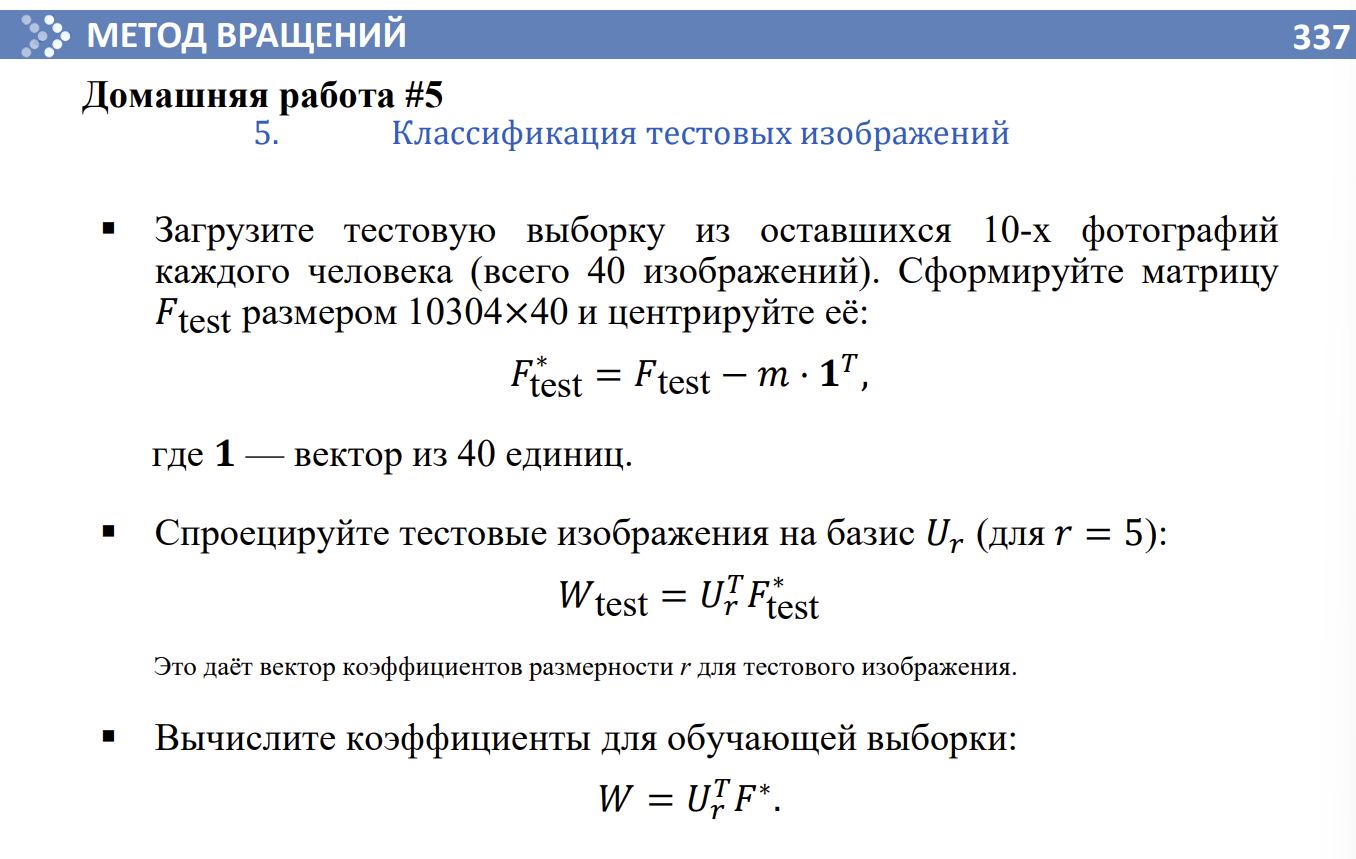

In [ ]:
m = 1/360 * np.sum(F,axis=1)
F_test_ = F_test - np.repeat(m,40).reshape(10304,40)
ur = np.array([i[2] for i in eig_val_vec_u[:r]])
W_test = ur@F_test_
W = ur@F_

###Классификация методом KNN с косинусовой метрикой расстояния

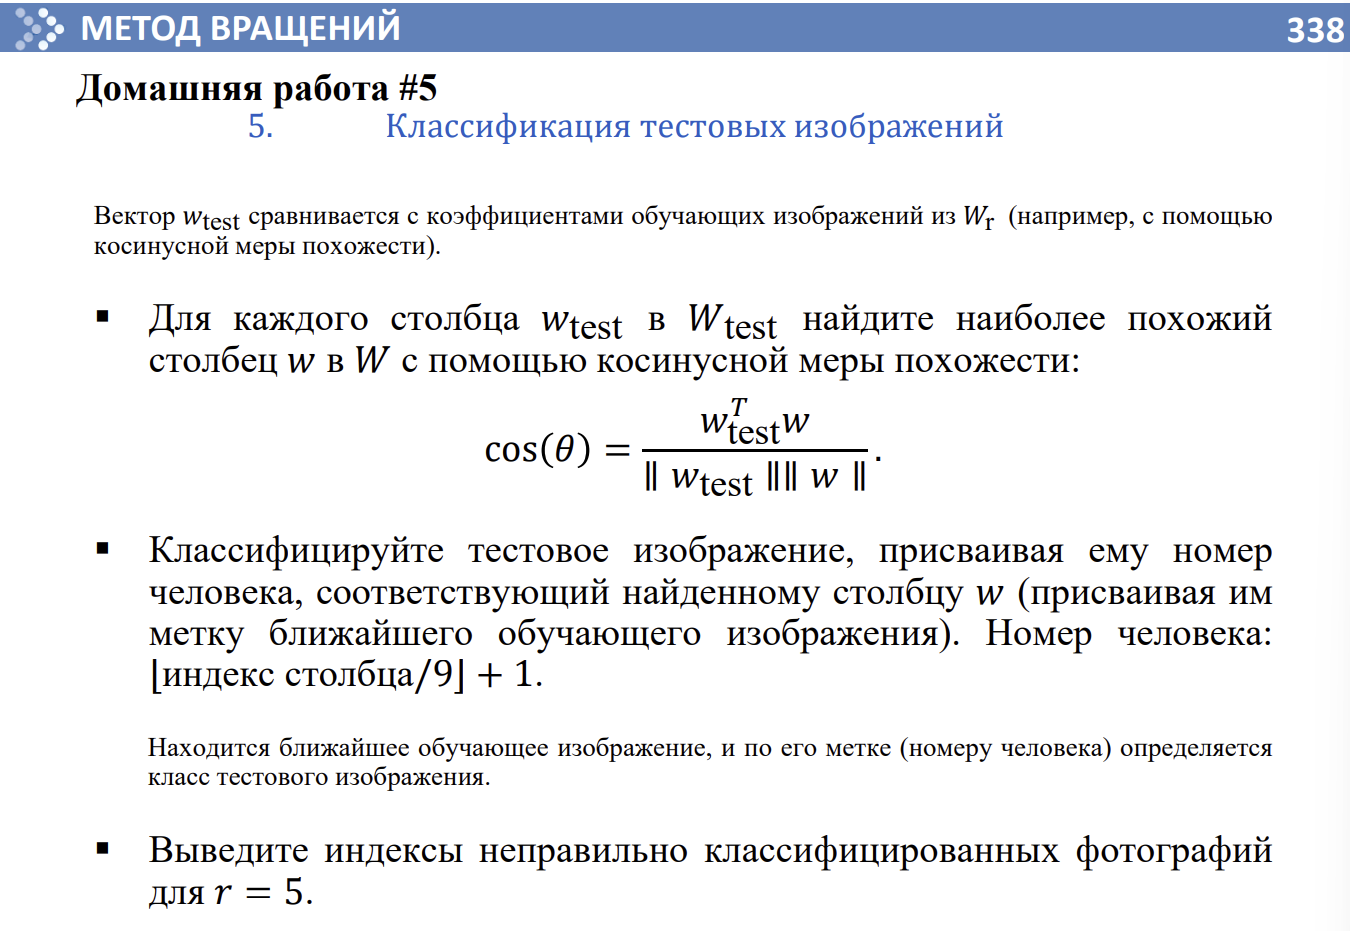

In [ ]:
def cosine_classification(W, W_test):
    W_norm = W / norm(W)
    Wt_norm = W_test / norm(W_test)

    sims = W_norm.T @ Wt_norm
    nearest = np.argmax(sims, axis=0)

    predicted_labels = nearest // 9 + 1
    true_labels = np.arange(1,41)
    #print(predicted_labels,true_labels)

    wrong = [i == j for i,j in zip(predicted_labels , true_labels)]
    return wrong


print(f'KNN правильно определил {sum(cosine_classification(W,W_test))} фотографий людей')
print(f'Индексы неправильной классификации: {np.where(np.array(cosine_classification(W,W_test)) == False)}')

KNN правильно определил 13 фотографий людей
Индексы неправильной классификации: (array([ 1,  2,  3,  4,  6,  8, 12, 14, 15, 16, 17, 19, 20, 21, 22, 24, 25,
       27, 28, 30, 31, 32, 33, 34, 35, 37, 39]),)


Большая ошибка связана с тем, что r маленькое для классификации, и датасет с 360 фотографиями небольшой в рамках задачи классификации лиц

###Вопросы

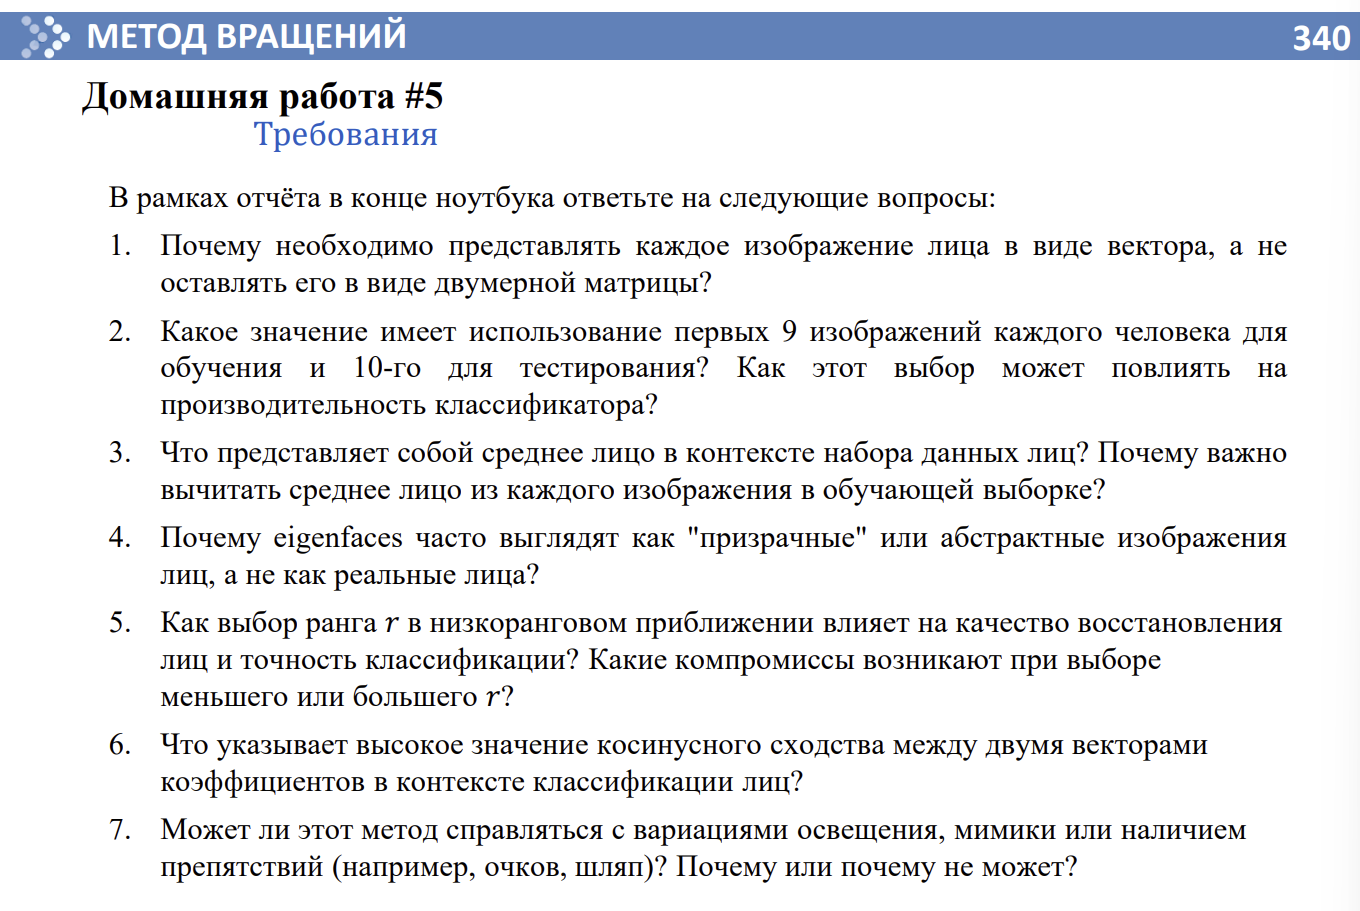

1. PCA работает с векторами чтобы найти зависимости между пикселями. Поэтому на входе изображение должны быть преобразовано в вектор.

2. Чем меньше количество обучающих данных, тем быстрее работает алгоритм, и тем меньше его точность. Соотношение 9:10 (10% всех данных) дает большое количество данных модели для хорошей обощающей способности.

3. Среднее лицо - вектор мат ожиданий каждого пикселя. Мы вычитаем его из выборки векторов фотографий, чтобы при PCA полученные векторы находились в центре координат (центрирование).

4. U_r не содержит всей информации о лице. Векторы U_r отобраны по количество объясняющей дисперсии, и содержат разные признаки. Они не обязаны быть визуально интерпретируемы.

5. Больше r -> больше информации -> качественнее классификация. Но также нельзя забывать о проклятии размерности, что при больших r вектора будут похожи на друг друга больше.

6. Фотографии схожи по набору признаков, которые нашел PCA

7. Может, но только если картинки с такими искажениями присутствовали в обучающей выборке.